In [1]:
import pandas as pd
from pathlib import Path

folder = Path("02_TABLES")   
tables = {f.stem: pd.read_csv(f) for f in sorted(folder.glob("*.csv"))}

for name, d in tables.items():
    print(f"{name:28} {d.shape}")

branches                     (80, 7)
customers                    (85000, 6)
data_dictionary              (169, 3)
delivery_shipments           (97660, 8)
employees                    (640, 6)
factories                    (6, 4)
import_partners              (16, 5)
import_shipments             (4200, 10)
inventory_transfer_items     (109614, 4)
inventory_transfers          (36500, 6)
marketing_campaigns          (2200, 11)
monthly_stock                (142784, 7)
operating_expenses           (47000, 7)
payroll                      (13210, 8)
products_catalog             (139, 6)
purchase_order_items         (103334, 7)
purchase_orders              (41500, 9)
sales_order_items            (1138536, 13)
sales_orders                 (540000, 13)
sales_payments               (540000, 6)
sales_returns                (28500, 9)
sku_variants                 (695, 5)
suppliers                    (48, 5)
warehouses                   (12, 5)


In [2]:
data_dict = tables["data_dictionary"]
display(data_dict)

for name, d in tables.items():
    print(f"\n{name}: {d.columns.tolist()}")

,table_name,field_name,description
0,branches.csv,branch_id,branch id
1,branches.csv,branch_name_ar,branch name ar
2,branches.csv,governorate_ar,governorate ar
3,branches.csv,city_ar,city ar
4,branches.csv,address_ar,address ar
...,...,...,...
164,warehouses.csv,warehouse_id,warehouse id
165,warehouses.csv,warehouse_label,warehouse label
166,warehouses.csv,governorate_ar,governorate ar
167,warehouses.csv,warehouse_kind,warehouse kind



branches: ['branch_id', 'branch_name_ar', 'governorate_ar', 'city_ar', 'address_ar', 'retail_location_type', 'opening_date']

customers: ['customer_id', 'customer_segment', 'customer_name_ar', 'governorate_ar', 'joined_date', 'age_band']

data_dictionary: ['table_name', 'field_name', 'description']

delivery_shipments: ['shipment_id', 'sales_order_id', 'ship_date', 'delivery_date', 'ship_to_governorate', 'carrier', 'shipping_fee_EGP', 'fulfillment_status']

employees: ['employee_id', 'employee_name_ar', 'branch_id', 'position_en', 'hire_date', 'salary_base_EGP_2026']

factories: ['factory_id', 'factory_name_ar', 'governorate_ar', 'production_focus']

import_partners: ['import_partner_id', 'partner_name', 'country', 'goods_category', 'shipping_terms']

import_shipments: ['import_shipment_id', 'import_partner_id', 'shipment_date', 'port_name', 'container_type', 'commodity_class', 'customs_value_USD', 'freight_USD', 'duty_and_tax_USD', 'destination_warehouse_id']

inventory_transfer_item

In [3]:
def shared_cols(a, b):
    return set(tables[a].columns) & set(tables[b].columns)

print(shared_cols("sales_orders", "sales_order_items"))
print(shared_cols("sales_orders", "customers"))
print(shared_cols("sales_order_items", "sku_variants"))

{'sales_order_id', 'order_date', 'branch_id'}
{'customer_id'}
{'product_id', 'sku_id'}


In [5]:
missing = ["sales_orders", "sales_order_items", "sales_payments", "sales_returns",
           "sku_variants", "products_catalog", "purchase_orders",
           "purchase_order_items", "payroll", "operating_expenses"]

for name in missing:
    print(f"\n{name}: {tables[name].columns.tolist()}")


sales_orders: ['sales_order_id', 'order_date', 'branch_id', 'customer_id', 'sales_channel', 'payment_method', 'items_count', 'gross_EGP', 'discount_EGP', 'net_before_tax_EGP', 'tax_EGP', 'paid_total_EGP', 'status']

sales_order_items: ['sales_line_id', 'sales_order_id', 'order_date', 'branch_id', 'sku_id', 'product_id', 'quantity', 'unit_price_EGP', 'gross_line_EGP', 'discount_line_EGP', 'net_line_EGP', 'unit_cost_EGP', 'margin_EGP']

sales_payments: ['payment_id', 'sales_order_id', 'payment_date', 'payment_method', 'amount_EGP', 'status']

sales_returns: ['return_id', 'sales_order_id', 'sales_line_id', 'return_date', 'sku_id', 'return_quantity', 'refund_amount_EGP', 'reason', 'refund_method']

sku_variants: ['sku_id', 'product_id', 'size', 'color_ar', 'price_multiplier']

products_catalog: ['product_id', 'product_name_ar', 'category_en', 'audience', 'listed_price_EGP', 'source_url']

purchase_orders: ['po_id', 'po_date', 'supplier_id', 'receiving_warehouse_id', 'po_status', 'currency

In [6]:
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", None)
display(tables["data_dictionary"])

,table_name,field_name,description
0,branches.csv,branch_id,branch id
1,branches.csv,branch_name_ar,branch name ar
2,branches.csv,governorate_ar,governorate ar
3,branches.csv,city_ar,city ar
4,branches.csv,address_ar,address ar
5,branches.csv,retail_location_type,retail location type
6,branches.csv,opening_date,opening date
7,branches.csv,source_url,source url
8,customers.csv,customer_id,customer id
9,customers.csv,customer_segment,customer segment


In [7]:
import pandas as pd

orders = pd.read_csv("02_TABLES/sales_orders.csv")

print(orders.shape)
display(orders.head())
orders.info()

(540000, 13)


,sales_order_id,order_date,branch_id,customer_id,sales_channel,payment_method,items_count,gross_EGP,discount_EGP,net_before_tax_EGP,tax_EGP,paid_total_EGP,status
0,SO00000001,2018-10-19,BR010,C0000006,Retail POS,Card POS,1,27.00,2.70,24.30,3.40,27.70,Completed
1,SO00000002,2018-10-19,BR047,C0000010,Retail POS,Cash,2,279.35,10.80,268.55,37.60,306.15,Completed
2,SO00000003,2018-10-19,BR013,NaN,E-commerce,Card POS,1,160.72,32.14,128.58,18.00,146.58,Delivered
3,SO00000004,2018-10-19,BR029,C0000025,Retail POS,Bank transfer,1,32.06,1.60,30.46,4.26,34.72,Completed
4,SO00000005,2018-10-19,BR009,NaN,Retail POS,Bank transfer,3,293.69,3.65,290.04,40.61,330.65,Completed


<class 'pandas.DataFrame'>
RangeIndex: 540000 entries, 0 to 539999
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   sales_order_id      540000 non-null  str    
 1   order_date          540000 non-null  str    
 2   branch_id           540000 non-null  str    
 3   customer_id         437039 non-null  str    
 4   sales_channel       540000 non-null  str    
 5   payment_method      540000 non-null  str    
 6   items_count         540000 non-null  int64  
 7   gross_EGP           540000 non-null  float64
 8   discount_EGP        540000 non-null  float64
 9   net_before_tax_EGP  540000 non-null  float64
 10  tax_EGP             540000 non-null  float64
 11  paid_total_EGP      540000 non-null  float64
 12  status              540000 non-null  str    
dtypes: float64(5), int64(1), str(7)
memory usage: 83.9 MB


In [8]:
orders["order_date"] = pd.to_datetime(orders["order_date"])

print("من:", orders["order_date"].min(), " إلى:", orders["order_date"].max())
print()
print(orders["status"].value_counts())
print()
print(orders["sales_channel"].value_counts())
print()
print("عدد الفروع:", orders["branch_id"].nunique())
print("Duplicates في الفواتير:", orders["sales_order_id"].duplicated().sum())

من: 2018-10-19 00:00:00  إلى: 2026-10-18 00:00:00

status
Completed             448120
Delivered              81152
Partially returned     10728
Name: count, dtype: int64

sales_channel
Retail POS              388171
E-commerce               97660
Wholesale / reseller     54169
Name: count, dtype: int64

عدد الفروع: 80
Duplicates في الفواتير: 0


In [9]:
branches = pd.read_csv("02_TABLES/branches.csv")

by_branch = (orders.groupby("branch_id")
             .agg(orders=("sales_order_id", "count"),
                  net_sales=("net_before_tax_EGP", "sum"))
             .reset_index()
             .merge(branches[["branch_id", "branch_name_ar", "governorate_ar", "opening_date"]],
                    on="branch_id", how="left")
             .sort_values("net_sales", ascending=False))

print("عدد الصفوف:", len(by_branch))
display(by_branch.head(10))
display(by_branch.tail(10))

عدد الصفوف: 80


,branch_id,orders,net_sales,branch_name_ar,governorate_ar,opening_date
2,BR003,6932,11434150.99,القطامية داون تاون,القاهرة,2/12/2020
73,BR074,6893,11274021.44,نجع حمادي,قنا,2/2/2020
14,BR015,6881,11244325.21,مدينتي الربيع,القاهرة,12/5/2019
48,BR049,6787,11011002.02,القومية,الشرقية,8/24/2019
26,BR027,6859,10935666.88,إمبابة,الجيزة,7/2/2019
29,BR030,6741,10931944.09,جليم,الإسكندرية,2/11/2020
22,BR023,6633,10903469.25,فيصل,الجيزة,10/16/2019
46,BR047,6878,10902863.28,شبراخيت,البحيرة,1/27/2019
9,BR010,6835,10893340.36,روكسي,القاهرة,9/7/2019
64,BR065,6703,10849999.01,ميدان الساعة,المنيا,12/26/2018


,branch_id,orders,net_sales,branch_name_ar,governorate_ar,opening_date
47,BR048,6640,10157998.92,مارينا 2,مطروح,7/25/2020
69,BR070,6721,10149980.13,مول الصفوة,دمياط,5/22/2019
4,BR005,6647,10117641.95,المعادي جراند مول,القاهرة,11/16/2018
52,BR053,6729,10108093.94,سمنود,الغربية,7/4/2019
66,BR067,6581,10107400.31,بني سويف الجديدة,بني سويف,2/18/2019
1,BR002,6800,10057326.94,السيدة زينب,القاهرة,2/19/2019
28,BR029,6648,10036423.76,الهانوفيل,الإسكندرية,3/7/2019
20,BR021,6638,9939578.39,العتبة,القاهرة,11/26/2018
40,BR041,6766,9922760.90,طلخا,الدقهلية,8/26/2020
35,BR036,6753,9844120.95,سان ستيفانو,الإسكندرية,6/14/2020



## Data Observations & Assumptions (Sales Orders)

### Assumptions
- **Sales metric:** `net_before_tax_EGP` (net of discount, excluding tax), since tax is not company revenue.
- **Order statuses included:** all three (`Completed`, `Delivered`, `Partially returned`). There are no cancelled orders.
- **Returns:** `Partially returned` orders (~2%) still carry their original amounts. Actual refunds will be handled separately from `sales_returns`.

### Observations
1. **Coverage:** 540,000 orders from 2018-10-19 to 2026-10-18, across 80 branches. No duplicate order IDs.
2. **Missing customers:** ~103K orders (~19%) have no `customer_id`, so any customer analysis only covers ~81% of orders.
3. **Branch sales are very close together:** the top branch (Katameya Downtown) has ~11.4M EGP and the lowest (San Stefano) ~9.8M EGP, a gap of only ~16%. Order counts per branch are all between ~6,600 and ~6,900. The ranking alone is therefore not a strong insight.
4. **E-commerce orders (97,660) equal the number of rows in `delivery_shipments`**, which suggests one shipment per online order (to be verified).

### Data Quality Concern
- Some branches appear to have orders **before their `opening_date`**. For example, Katameya Downtown opened in Feb 2020 but is the top branch, even though the data starts in Oct 2018. A branch opened in 2020 should have far fewer total sales than one operating since 2018.

### Questions for the data owner
1. Is `opening_date` the real opening date, or could it be a renovation/relocation date?
2. Are orders dated before a branch's opening date valid?
3. Why do ~19% of orders have no customer ID (walk-in customers, wholesale)?

### Next step
- Check how many branches have orders before `opening_date`, then compare branches on **monthly sales per active month** instead of total sales.


In [10]:
branches["opening_date"] = pd.to_datetime(branches["opening_date"])

first_order = (orders.groupby("branch_id")["order_date"].min()
               .rename("first_order_date").reset_index())

check = branches[["branch_id", "branch_name_ar", "opening_date"]].merge(first_order, on="branch_id")
check["orders_before_opening"] = check["first_order_date"] < check["opening_date"]

print(check["orders_before_opening"].value_counts())
display(check.sort_values("opening_date", ascending=False).head(10))

orders_before_opening
True    80
Name: count, dtype: int64


,branch_id,branch_name_ar,opening_date,first_order_date,orders_before_opening
16,BR017,زهراء المعادي,2020-08-29,2018-10-19,True
40,BR041,طلخا,2020-08-26,2018-10-19,True
77,BR078,شرق البندر,2020-08-10,2018-10-19,True
11,BR012,البطراوي,2020-08-07,2018-10-20,True
55,BR056,سقالة,2020-07-26,2018-10-19,True
47,BR048,مارينا 2,2020-07-25,2018-10-19,True
51,BR052,المحلة الكبرى,2020-07-04,2018-10-19,True
41,BR042,سعد زغلول,2020-06-17,2018-10-19,True
35,BR036,سان ستيفانو,2020-06-14,2018-10-19,True
49,BR050,صيدناوي,2020-06-01,2018-10-19,True


### Data Quality Finding (confirmed)
- **All 80 branches** have orders dated before their `opening_date`, and nearly all start on the first day of the data (2018-10-19).
- Conclusion: `opening_date` does not reflect when a branch started selling, so it will **not** be used to adjust or filter branch comparisons.
- Since every branch is active over the same period, comparing total sales across branches is fair.
- To confirm with the data owner: what does `opening_date` represent?

In [11]:
orders["year"] = orders["order_date"].dt.year

per_year = (orders.pivot_table(index="branch_id", columns="year",
                               values="sales_order_id", aggfunc="count"))

display(per_year.loc[["BR017", "BR041", "BR078", "BR003"]])
print(per_year.sum().round(0))

year,2018,2019,2020,2021,2022,2023,2024,2025,2026
branch_id,,,,,,,,,
BR017,107,569,593,674,758,928,992,1171,980
BR041,92,538,610,685,780,909,1045,1129,978
BR078,92,523,598,670,782,952,1054,1186,989
BR003,140,598,557,656,791,934,1044,1189,1023


year
2018     8576
2019    44108
2020    46425
2021    53269
2022    61934
2023    72233
2024    81885
2025    93384
2026    78186
dtype: int64


### Trend Finding
- Order volume roughly **doubled** between 2019 (~44K) and 2025 (~93K), with steady yearly growth of ~14-18% from 2021 to 2025.
- All branches show the same growth pattern, regardless of their `opening_date`.
- 2018 (from Oct 19) and 2026 (to Oct 18) are **partial years** and must not be compared directly with full years.
- Order count is not sales value: part of the growth in revenue may come from price increases. To be checked next.

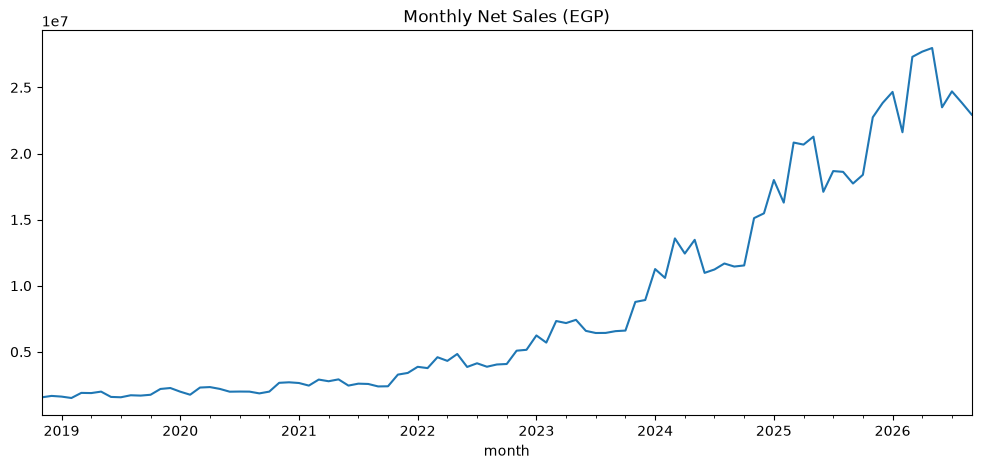

year,2019,2020,2021,2022,2023,2024,2025
order_date,,,,,,,
1,7.5,7.7,8.1,7.5,7.4,7.6,7.7
2,7.0,6.8,7.5,7.3,6.8,7.1,7.0
3,8.7,8.9,8.9,8.9,8.7,9.1,8.9
4,8.7,9.1,8.5,8.4,8.5,8.4,8.8
5,9.2,8.5,8.9,9.4,8.8,9.1,9.1
6,7.3,7.7,7.5,7.5,7.8,7.4,7.3
7,7.2,7.8,7.9,8.0,7.6,7.5,8.0
8,7.9,7.7,7.8,7.5,7.6,7.9,7.9
9,7.8,7.2,7.3,7.8,7.8,7.7,7.6


In [13]:
import matplotlib.pyplot as plt
orders["month"] = orders["order_date"].dt.to_period("M")

monthly = (orders.groupby("month")
           .agg(orders=("sales_order_id", "count"),
                net_sales=("net_before_tax_EGP", "sum")))

monthly["net_sales"].iloc[1:-1].plot(figsize=(12, 5), title="Monthly Net Sales (EGP)")
plt.show()

full = orders[orders["year"].between(2019, 2025)]
season = full.pivot_table(index=full["order_date"].dt.month,
                          columns="year",
                          values="net_before_tax_EGP",
                          aggfunc="sum")
display((season / season.sum() * 100).round(1))

In [14]:
yearly = (orders.groupby("year")
          .agg(orders=("sales_order_id", "count"),
               net_sales=("net_before_tax_EGP", "sum"),
               avg_order_value=("net_before_tax_EGP", "mean")))
display(yearly.round(0))

,orders,net_sales,avg_order_value
year,,,
2018,8576,3734869.0,436.0
2019,44108,21620205.0,490.0
2020,46425,25709342.0,554.0
2021,53269,32716862.0,614.0
2022,61934,51578474.0,833.0
2023,72233,84147935.0,1165.0
2024,81885,148782350.0,1817.0
2025,93384,234138548.0,2507.0
2026,78186,238845590.0,3055.0


### Yearly Growth: Volume vs Value
- Between 2019 and 2025: order count grew ~2.1x, average order value (AOV) ~5.1x, total net sales ~10.8x. Roughly two thirds of the growth comes from higher AOV, not more orders.
- Order count grows steadily (~13-17% per year). AOV growth accelerates sharply from 2022 (+36%, +40%, +56%, +38% in 2022-2025).
- 2026 is a partial year (to Oct 18), yet its net sales (238.8M EGP) already exceed full-year 2025 (234.1M EGP).
- All figures are **nominal** (not adjusted for inflation). The 2022 acceleration is consistent with inflation/currency effects, but this is only a hypothesis; the data may also be synthetic.

### Next step
- Split AOV growth into items per order vs average net value per item.
- Questions for the data owner: were there price increases from 2022? Is there a currency or inflation adjustment we should apply?

In [15]:
y2 = (orders.groupby("year")
      .agg(avg_items=("items_count", "mean"),
           total_items=("items_count", "sum"),
           net_sales=("net_before_tax_EGP", "sum")))
y2["avg_net_per_item"] = y2["net_sales"] / y2["total_items"]
display(y2.round(2))

,avg_items,total_items,net_sales,avg_net_per_item
year,,,,
2018,2.12,18151,3.734869e+06,205.77
2019,2.10,92752,2.162020e+07,233.10
2020,2.12,98194,2.570934e+07,261.82
2021,2.10,112093,3.271686e+07,291.87
2022,2.11,130596,5.157847e+07,394.95
2023,2.11,152500,8.414793e+07,551.79
2024,2.11,172609,1.487824e+08,861.96
2025,2.11,196827,2.341385e+08,1189.57
2026,2.11,164814,2.388456e+08,1449.18


### AOV Breakdown: Items per Order vs Price per Item
- Average items per order is flat (~2.1) in every year, so higher AOV is **not** caused by customers buying more items per order.
- Average net value per item grew from ~233 EGP (2019) to ~1,190 EGP (2025), about 5.1x, which matches the AOV growth.
- Units sold grew ~2.1x (92.8K to 196.8K), in line with order growth.
- Yearly growth in value per item: +12% (2020), +11% (2021), +35% (2022), +40% (2023), +56% (2024), +38% (2025), +22% (2026 YTD, partial year).
- Average items per order (2.11) matches order lines / orders (1,138,536 / 540,000), so `items_count` counts order lines, not order lines; `quantity` in `sales_order_items` should be checked separately.

### Open question
- Is the rise in value per item due to price increases on the same products, or a shift toward more expensive products (mix)? Next step: compare unit price of the same products across years.

In [ ]:
items = pd.read_csv("02_TABLES/sales_order_items.csv",
                    usecols=["order_date", "product_id", "quantity",
                             "unit_price_EGP", "net_line_EGP"])
items["year"] = pd.to_datetime(items["order_date"]).dt.year

print(items.shape)

display(items.groupby("year")["unit_price_EGP"].mean().round(0))

top3 = items["product_id"].value_counts().head(3).index
display(items[items["product_id"].isin(top3)]
        .pivot_table(index="product_id", columns="year",
                     values="unit_price_EGP", aggfunc="mean").round(0))

(1138536, 6)


year
2018     72.0
2019     81.0
2020     91.0
2021    101.0
2022    137.0
2023    193.0
2024    301.0
2025    416.0
2026    509.0
Name: unit_price_EGP, dtype: float64

year,2018,2019,2020,2021,2022,2023,2024,2025,2026
product_id,,,,,,,,,
PR0060,323.0,368.0,413.0,458.0,620.0,872.0,1350.0,1881.0,2295.0
PR0082,102.0,116.0,131.0,145.0,197.0,276.0,428.0,597.0,726.0
PR0086,118.0,136.0,152.0,169.0,229.0,322.0,501.0,694.0,849.0


### Price Check (same products across years)
- Average unit price rose from ~81 EGP (2019) to ~416 EGP (2025), about 5.1x, matching the growth in AOV.
- The three best-selling products (PR0060, PR0082, PR0086) show the same price path: roughly 5.1x between 2019 and 2025, with identical yearly growth rates (+11-12% up to 2021, then +35%, +41%, +55%, +39%, and +22% in 2026 YTD).
- Conclusion: the rise in sales value comes from **price increases on the same products**, not from a shift to pricier products. The identical growth pattern across products suggests a single uniform price factor (data may be synthetic).
- Implication: nominal sales in EGP overstate real growth. Real volume grew only ~2.1x. Cross-year comparisons should use units or margin %, not raw EGP.

### Correction
- Earlier "total_items" was the sum of `items_count`, which counts **order lines**, not units. Units sold must be taken from `quantity` in `sales_order_items`.

### Next step
- Compute units sold and margin % per year (does margin % change as prices rise?), then profitability by category.

In [17]:
items = pd.read_csv("02_TABLES/sales_order_items.csv",
                    usecols=["order_date", "quantity", "net_line_EGP", "margin_EGP"])
items["year"] = pd.to_datetime(items["order_date"]).dt.year

y = (items.groupby("year")
     .agg(lines=("quantity", "count"),
          units=("quantity", "sum"),
          net=("net_line_EGP", "sum"),
          margin=("margin_EGP", "sum")))
y["margin_pct"] = (y["margin"] / y["net"] * 100).round(1)
y["units_growth_pct"] = (y["units"].pct_change() * 100).round(1)
display(y)

print(y["net"].sum(), orders["net_before_tax_EGP"].sum())

,lines,units,net,margin,margin_pct,units_growth_pct
year,,,,,,
2018,18151,54593,3.734869e+06,1439846.12,38.6,NaN
2019,92752,277858,2.162020e+07,8282661.45,38.3,409.0
2020,98194,293811,2.570934e+07,9851333.48,38.3,5.7
2021,112093,336439,3.271686e+07,12532489.27,38.3,14.5
2022,130596,391843,5.157847e+07,19678995.84,38.2,16.5
2023,152500,457698,8.414793e+07,32285272.98,38.4,16.8
2024,172609,512715,1.487824e+08,57115997.00,38.4,12.0
2025,196827,586290,2.341385e+08,89786828.07,38.3,14.4
2026,164814,487408,2.388456e+08,91584875.29,38.3,-16.9


841274176.32 841274176.3199999


### Units and Margin by Year
- **Margin % is flat at ~38.3% every year**, so unit costs rose in the same proportion as prices. Margin in EGP grew ~10.8x (8.3M in 2019 to 89.8M in 2025), driven by price increases, not better profitability.
- **Units sold** grew ~2.1x between 2019 and 2025 (277.9K to 586.3K), in line with order growth. Yearly unit growth: +5.7% (2020), +14.5% (2021), +16.5% (2022), +16.8% (2023), +12.0% (2024), +14.4% (2025).
- On average each order line holds ~3 units (~6 units per order).
- The +409% (2019) and -16.9% (2026) growth figures are artifacts of partial years (2018 and 2026) and are **not** real changes.
- Net sales per year match between `sales_order_items` and `sales_orders`, so the two tables are consistent.
- Uniform price growth and a constant margin % suggest synthetic data.

### To check later
- Compare Jan 1 - Oct 18 of 2026 against the same period of 2025 to see whether unit growth is slowing.

In [18]:
items = pd.read_csv("02_TABLES/sales_order_items.csv",
                    usecols=["product_id", "quantity", "net_line_EGP", "margin_EGP"])
products = pd.read_csv("02_TABLES/products_catalog.csv")

df = items.merge(products[["product_id", "category_en", "audience"]],
                 on="product_id", how="left", validate="m:1")
print(len(items), len(df))   # لازم يتساووا
print("منتجات من غير فئة:", df["category_en"].isna().sum())

cat = (df.groupby("category_en")
       .agg(units=("quantity", "sum"),
            net=("net_line_EGP", "sum"),
            margin=("margin_EGP", "sum")))
cat["margin_pct"] = (cat["margin"] / cat["net"] * 100).round(1)
cat["share_of_sales_pct"] = (cat["net"] / cat["net"].sum() * 100).round(1)
display(cat.sort_values("net", ascending=False))

1138536 1138536
منتجات من غير فئة: 0


,units,net,margin,margin_pct,share_of_sales_pct
category_en,,,,,
Men boxers,381819,1.941991e+08,74185815.69,38.2,23.1
Men tops,442948,1.645242e+08,63199254.94,38.4,19.6
Socks,911138,1.161791e+08,44605474.49,38.4,13.8
Men underwear,189180,5.306302e+07,20415784.39,38.5,6.3
Women pajamas,78090,5.021588e+07,19243672.55,38.3,6.0
Women tops,339951,4.853651e+07,18625550.50,38.4,5.8
Girls pajamas,158994,3.897353e+07,14967186.39,38.4,4.6
Boys pajamas,156975,3.818746e+07,14666966.34,38.4,4.5
Home textiles,98800,3.364654e+07,12831206.83,38.1,4.0


,units_share_pct,share_of_sales_pct,avg_unit_price,products,sales_per_product_M
category_en,,,,,
Men boxers,11.2,23.1,509.0,7,27.74
Men tops,13.0,19.6,371.0,9,18.28
Socks,26.8,13.8,128.0,76,1.53
Men underwear,5.6,6.3,280.0,5,10.61
Women pajamas,2.3,6.0,643.0,2,25.11
Women tops,10.0,5.8,143.0,7,6.93
Girls pajamas,4.7,4.6,245.0,4,9.74
Boys pajamas,4.6,4.5,243.0,4,9.55
Home textiles,2.9,4.0,341.0,4,8.41


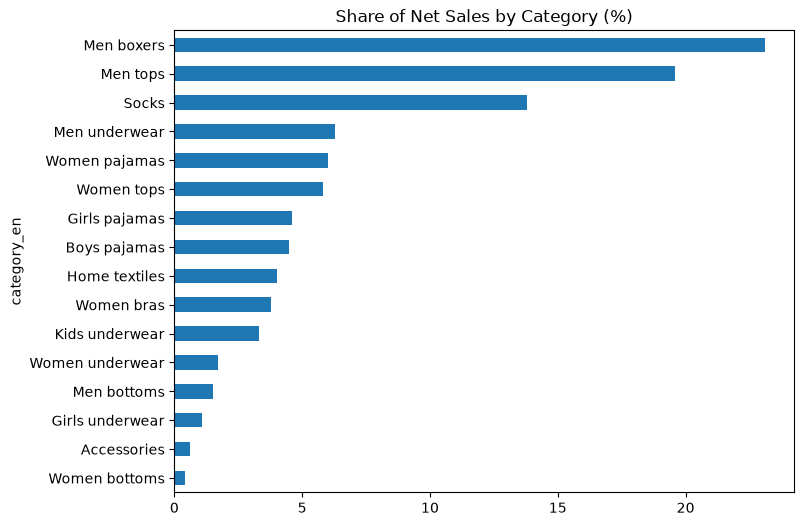

In [19]:
cat["units_share_pct"] = (cat["units"] / cat["units"].sum() * 100).round(1)
cat["avg_unit_price"] = (cat["net"] / cat["units"]).round(0)
cat["products"] = products.groupby("category_en")["product_id"].nunique()
cat["sales_per_product_M"] = (cat["net"] / cat["products"] / 1e6).round(2)

view = cat[["units_share_pct", "share_of_sales_pct", "avg_unit_price",
            "products", "sales_per_product_M"]]
display(view.sort_values("share_of_sales_pct", ascending=False))

cat["share_of_sales_pct"].sort_values().plot(kind="barh", figsize=(8, 6),
                                             title="Share of Net Sales by Category (%)")
plt.show()

In [20]:
items = pd.read_csv("02_TABLES/sales_order_items.csv",
                    usecols=["order_date", "product_id", "quantity"])
items["year"] = pd.to_datetime(items["order_date"]).dt.year

df = items.merge(products[["product_id", "category_en"]],
                 on="product_id", how="left", validate="m:1")

mix = (df[df["year"].between(2019, 2025)]
       .pivot_table(index="category_en", columns="year",
                    values="quantity", aggfunc="sum"))

display((mix / mix.sum() * 100).round(1))

year,2019,2020,2021,2022,2023,2024,2025
category_en,,,,,,,
Accessories,0.8,0.7,0.7,0.7,0.7,0.7,0.7
Boys pajamas,4.9,4.5,4.7,4.7,4.6,4.5,4.5
Girls pajamas,4.8,4.5,4.6,4.7,4.8,4.6,4.7
Girls underwear,1.1,1.2,1.1,1.1,1.1,1.1,1.0
Home textiles,2.9,3.0,2.9,2.8,2.9,2.9,2.9
Kids underwear,8.7,8.8,8.5,8.8,8.7,8.8,8.7
Men bottoms,2.2,2.2,2.2,2.2,2.1,2.1,2.2
Men boxers,11.2,11.3,11.2,11.2,11.1,11.6,11.2
Men tops,12.8,13.0,12.9,13.0,13.1,13.0,13.1


In [21]:
d = orders[orders["year"].between(2019, 2025)]

share = d.pivot_table(index="year", columns="sales_channel",
                      values="sales_order_id", aggfunc="count")
display((share.div(share.sum(axis=1), axis=0) * 100).round(1))

ch = (d.groupby("sales_channel")
      .agg(orders=("sales_order_id", "count"),
           avg_items=("items_count", "mean"),
           avg_order_value=("net_before_tax_EGP", "mean"),
           avg_discount_pct=("discount_EGP", lambda s: 0)))   # مؤقت
ch["avg_discount_pct"] = (d.groupby("sales_channel")["discount_EGP"].sum()
                          / d.groupby("sales_channel")["gross_EGP"].sum() * 100)
ch["returned_pct"] = (d.assign(r=d["status"].eq("Partially returned"))
                      .groupby("sales_channel")["r"].mean() * 100)
display(ch.round(1))

sales_channel,E-commerce,Retail POS,Wholesale / reseller
year,,,
2019,17.7,72.2,10.1
2020,17.7,72.1,10.2
2021,18.1,71.6,10.2
2022,18.0,72.0,10.0
2023,18.1,71.7,10.1
2024,18.0,72.0,10.0
2025,18.4,71.6,10.0


,orders,avg_items,avg_order_value,avg_discount_pct,returned_pct
sales_channel,,,,,
E-commerce,81805,2.1,913.9,4.3,1.9
Retail POS,325742,2.1,905.8,4.3,2.0
Wholesale / reseller,45691,2.1,5009.4,4.4,2.0


In [22]:
returns = pd.read_csv("02_TABLES/sales_returns.csv")
ship = pd.read_csv("02_TABLES/delivery_shipments.csv")

# المرتجعات
print(returns.shape)
display(returns["reason"].value_counts(normalize=True).mul(100).round(1))
display(returns["refund_method"].value_counts(normalize=True).mul(100).round(1))

# التوصيل
ship["ship_date"] = pd.to_datetime(ship["ship_date"])
ship["delivery_date"] = pd.to_datetime(ship["delivery_date"])
ship["days"] = (ship["delivery_date"] - ship["ship_date"]).dt.days

display(ship["fulfillment_status"].value_counts(normalize=True).mul(100).round(1))
display(ship.groupby("carrier")[["days", "shipping_fee_EGP"]].mean().round(1))

(28500, 9)


reason
Other           20.3
Size issue      20.2
Defect claim    20.0
Exchange        19.8
Wrong item      19.8
Name: proportion, dtype: float64

refund_method
Card reversal    33.9
Cash             33.1
Wallet           33.0
Name: proportion, dtype: float64

fulfillment_status
Delivered    97.0
Delayed       3.0
Name: proportion, dtype: float64

,days,shipping_fee_EGP
carrier,,
Express carrier,4.0,51.1
In-house delivery,4.0,51.4
Local courier,4.0,51.5


In [24]:
print("فواتير فيها مرتجع:", returns["sales_order_id"].nunique())
print("فواتير حالتها Partially returned:", (orders["status"] == "Partially returned").sum())

flagged = set(orders.loc[orders["status"] == "Partially returned", "sales_order_id"])
print("مرتجعات على فواتير مش Partially returned:",
      (~returns["sales_order_id"].isin(flagged)).sum())

print("سطور اتعمل عليها أكتر من مرتجع:", returns["sales_line_id"].duplicated().sum())
print("مرتجعات لسطور مش موجودة في الأصناف:",
      (~returns["sales_line_id"].isin(items_all["sales_line_id"])).sum()
      if "items_all" in globals() else "اقري جدول الأصناف الأول")

فواتير فيها مرتجع: 28500
فواتير حالتها Partially returned: 10728
مرتجعات على فواتير مش Partially returned: 27940
سطور اتعمل عليها أكتر من مرتجع: 0
مرتجعات لسطور مش موجودة في الأصناف: اقري جدول الأصناف الأول


In [25]:
items_chk = pd.read_csv("02_TABLES/sales_order_items.csv",
                        usecols=["sales_line_id", "sales_order_id", "order_date",
                                 "quantity", "net_line_EGP"])

r = returns.merge(items_chk, on="sales_line_id", how="left",
                  suffixes=("", "_item"), validate="1:1")

print("مرتجعات لسطور مش موجودة:", r["quantity"].isna().sum())
print("رقم الفاتورة مش مطابق للسطر:", (r["sales_order_id"] != r["sales_order_id_item"]).sum())

r["return_date"] = pd.to_datetime(r["return_date"])
r["order_date"] = pd.to_datetime(r["order_date"])
print("مرتجع قبل تاريخ البيع:", (r["return_date"] < r["order_date"]).sum())
print("كمية مرتجعة أكبر من المباعة:", (r["return_quantity"] > r["quantity"]).sum())

r["refund_ratio"] = r["refund_amount_EGP"] / r["net_line_EGP"]
display(r["refund_ratio"].describe().round(2))

# نسبة المرتجعات بالقناة، من جدول المرتجعات هذه المرة
o = orders.merge(returns[["sales_order_id"]].assign(has_return=1),
                 on="sales_order_id", how="left")
o["has_return"] = o["has_return"].fillna(0)
display((o.groupby("sales_channel")["has_return"].mean() * 100).round(2))

مرتجعات لسطور مش موجودة: 0
رقم الفاتورة مش مطابق للسطر: 0
مرتجع قبل تاريخ البيع: 0
كمية مرتجعة أكبر من المباعة: 0


count    28500.00
mean         0.80
std          0.26
min          0.02
25%          0.54
50%          0.92
75%          0.99
max          1.25
Name: refund_ratio, dtype: float64

sales_channel
E-commerce              5.26
Retail POS              5.27
Wholesale / reseller    5.36
Name: has_return, dtype: float64

In [26]:
r["qty_ratio"] = r["return_quantity"] / r["quantity"]
r["expected_ratio"] = r["qty_ratio"]

print("استرداد أكبر من قيمة السطر:", (r["refund_ratio"] > 1).sum())
print("استرداد أكبر من القيمة + 14% ضريبة:", (r["refund_ratio"] > 1.15).sum())

# الاسترداد مقارنة بنسبة القطع المرتجعة
r["refund_vs_expected"] = r["refund_ratio"] / r["expected_ratio"]
display(r["refund_vs_expected"].describe().round(2))

استرداد أكبر من قيمة السطر: 5677
استرداد أكبر من القيمة + 14% ضريبة: 455


count    28500.00
mean         0.98
std          0.07
min          0.87
25%          0.93
50%          0.97
75%          1.02
max          1.25
Name: refund_vs_expected, dtype: float64

### Refund Amount Check
- Refund amounts are consistent with returned quantity: the ratio of actual refund to the pro-rata line value has mean 0.98 and median 0.97, with half of returns between 0.93 and 1.02 (range 0.87-1.25).
- 5,677 returns (~20%) are refunded above the net line value. Most (about 5,222) are within +15%, which could be explained by tax (~14%), but refunds are not consistently tax-inclusive (mean ratio 0.98, not ~1.14).
- Only 455 returns (1.6%) exceed 1.15x the pro-rata value (max 1.25x). Minor and unexplained.
- Question for the data owner: do refunds include tax, and why do some exceed 115% of the line value?

### Next step
- Inspect `operating_expenses`, `payroll` and `employees` (period covered, who the expense IDs belong to, expense categories) before building a branch profit table.
- Note: payroll has ~20 monthly records per employee (13,210 rows / 640 employees), so it likely covers a shorter period than the 8 years of sales. Compare matching periods only.

In [27]:
exp = pd.read_csv("02_TABLES/operating_expenses.csv")
pay = pd.read_csv("02_TABLES/payroll.csv")
emp = pd.read_csv("02_TABLES/employees.csv")

print(exp.shape, pay.shape, emp.shape)

print("\n--- operating_expenses ---")
print("فترة المصاريف:", exp["expense_date"].min(), "إلى", exp["expense_date"].max())
print("عدد القيم المختلفة في branch_or_department_id:", exp["branch_or_department_id"].nunique())
display(exp["branch_or_department_id"].astype(str).str[:2].value_counts())
display(exp["expense_category"].value_counts())

print("\n--- payroll ---")
print("فترة المرتبات:", pay["pay_month"].min(), "إلى", pay["pay_month"].max())
print("موظفين في المرتبات:", pay["employee_id"].nunique(), "| موظفين في employees:", len(emp))
print("موظفين من غير فرع:", emp["branch_id"].isna().sum())

(47000, 7) (13210, 8) (640, 6)

--- operating_expenses ---
فترة المصاريف: 2018-10-19 إلى 2026-10-18
عدد القيم المختلفة في branch_or_department_id: 92


branch_or_department_id
BR    37592
WH     9408
Name: count, dtype: int64

expense_category
Marketing                 4856
Travel                    4779
Logistics                 4742
Maintenance               4715
Rent                      4692
Utilities                 4664
General administration    4652
Insurance                 4646
Supplies                  4645
IT & software             4609
Name: count, dtype: int64


--- payroll ---
فترة المرتبات: 2018-10 إلى 2026-10
موظفين في المرتبات: 640 | موظفين في employees: 640
موظفين من غير فرع: 0


In [28]:
exp["expense_date"] = pd.to_datetime(exp["expense_date"])
exp["year"] = exp["expense_date"].dt.year
exp["type"] = exp["branch_or_department_id"].str[:2]

# 1) المصاريف بالسنة والنوع
display(exp.pivot_table(index="year", columns="type", values="amount_EGP",
                        aggfunc="sum").round(0))

# 2) المصاريف بالفئة (إجمالي الفروع بس)
display(exp[exp["type"] == "BR"].groupby("expense_category")["amount_EGP"]
        .agg(["sum", "mean"]).sort_values("sum", ascending=False).round(0))

# 3) المرتبات بالسنة وعدد الموظفين
pay["year"] = pay["pay_month"].str[:4].astype(int)
display(pay.groupby("year").agg(employees=("employee_id", "nunique"),
                                records=("payroll_id", "count"),
                                net_paid=("net_paid_EGP", "sum")).round(0))

# 4) مقارنة بالمبيعات والهامش
cmp = (orders.groupby("year")["net_before_tax_EGP"].sum() * 0.383).rename("gross_margin_est")
display(cmp.round(0))

type,BR,WH
year,,
2018,892054.0,245841.0
2019,5005657.0,1281889.0
2020,5785833.0,1433747.0
2021,6309841.0,1556332.0
2022,8580382.0,2257732.0
2023,12039097.0,3240817.0
2024,18768869.0,4571427.0
2025,25691725.0,6214662.0
2026,25479685.0,6288079.0


,sum,mean
expense_category,,
Rent,18541409.0,4921.0
Utilities,17932233.0,4877.0
Marketing,9486119.0,2444.0
Travel,9253498.0,2420.0
Logistics,9192930.0,2401.0
General administration,8950485.0,2412.0
Insurance,8915543.0,2374.0
Maintenance,8851217.0,2357.0
Supplies,8727014.0,2362.0


,employees,records,net_paid
year,,,
2018,3,5,9872.0
2019,62,350,630865.0
2020,164,1267,2519962.0
2021,264,2194,4756587.0
2022,321,2559,7604088.0
2023,322,2580,10993527.0
2024,283,2401,15760626.0
2025,185,1529,13790701.0
2026,68,325,3456287.0


year
2018     1430455.0
2019     8280538.0
2020     9846678.0
2021    12530558.0
2022    19754556.0
2023    32228659.0
2024    56983640.0
2025    89675064.0
2026    91477861.0
Name: gross_margin_est, dtype: float64

In [29]:
emp["hire_date"] = pd.to_datetime(emp["hire_date"])
pay["pay_month"] = pd.to_datetime(pay["pay_month"])

g = (pay.groupby("employee_id")["pay_month"]
     .agg(first="min", last="max", months="count").reset_index())
chk = emp[["employee_id", "branch_id", "hire_date"]].merge(g, on="employee_id", validate="1:1")

# 1) كام شهر مرتب لكل موظف؟
display(chk["months"].describe().round(1))

# 2) هل في موظفين وقفوا ياخدوا مرتب قبل آخر شهر؟
print("موظفين آخر مرتب ليهم قبل 2026-10:", (chk["last"] < "2026-10-01").sum())

# 3) هل أول مرتب = شهر التعيين؟
print("أول مرتب في غير شهر التعيين:",
      (chk["first"] != chk["hire_date"].dt.to_period("M").dt.to_timestamp()).sum())

# 4) فيه شهور ناقصة (فجوات)؟
span = (chk["last"].dt.year - chk["first"].dt.year) * 12 + (chk["last"].dt.month - chk["first"].dt.month) + 1
print("موظفين عندهم فجوات:", (span != chk["months"]).sum())

# 5) التعيينات كل سنة
display(chk["hire_date"].dt.year.value_counts().sort_index())

count    640.0
mean      20.6
std        7.5
min        9.0
25%       14.0
50%       20.0
75%       27.0
max       34.0
Name: months, dtype: float64

موظفين آخر مرتب ليهم قبل 2026-10: 630
أول مرتب في غير شهر التعيين: 600
موظفين عندهم فجوات: 0


hire_date
2018     22
2019    104
2020    138
2021    116
2022    126
2023    106
2024     28
Name: count, dtype: int64

In [30]:
# 1) الفرق بين شهر التعيين وأول مرتب
chk["hire_month"] = chk["hire_date"].dt.to_period("M").dt.to_timestamp()
chk["offset_months"] = ((chk["first"].dt.year - chk["hire_month"].dt.year) * 12
                        + (chk["first"].dt.month - chk["hire_month"].dt.month))
display(chk["offset_months"].describe().round(1))

# 2) مرتب الجدول مقابل مرتب employees كل سنة
p = pay.merge(emp[["employee_id", "salary_base_EGP_2026"]], on="employee_id")
p["ratio"] = p["base_salary_EGP"] / p["salary_base_EGP_2026"]
display(p.groupby(p["pay_month"].dt.year)["ratio"].mean().round(2))

# 3) آخر شهور فيها مرتبات
display(chk["last"].dt.to_period("M").value_counts().sort_index().tail(12))

# 4) موظفين لكل فرع
display(emp.groupby("branch_id").size().describe().round(1))

count    640.0
mean       8.2
std        5.1
min        0.0
25%        4.0
50%        8.0
75%       13.0
max       16.0
Name: offset_months, dtype: float64

pay_month
2018    0.21
2019    0.16
2020    0.16
2021    0.17
2022    0.24
2023    0.33
2024    0.52
2025    0.73
2026    0.85
Name: ratio, dtype: float64

last
2025-11     7
2025-12     9
2026-01     9
2026-02    12
2026-03     5
2026-04    14
2026-05     4
2026-06     5
2026-07     4
2026-08     2
2026-09     3
2026-10    10
Freq: M, Name: count, dtype: int64

count    80.0
mean      8.0
std       0.0
min       8.0
25%       8.0
50%       8.0
75%       8.0
max       8.0
dtype: float64

In [33]:
yrs = range(2019, 2026)

# 1) هامش كل فرع
it = pd.read_csv("02_TABLES/sales_order_items.csv",
                 usecols=["branch_id", "order_date", "net_line_EGP", "margin_EGP"])
it["year"] = pd.to_datetime(it["order_date"]).dt.year
it = it[it["year"].isin(yrs)]
b = it.groupby("branch_id").agg(net=("net_line_EGP", "sum"), margin=("margin_EGP", "sum"))

# 2) مصاريف الفروع
e = exp[(exp["type"] == "BR") & exp["year"].isin(yrs)]
b["expenses"] = e.groupby("branch_or_department_id")["amount_EGP"].sum()

# 3) مرتبات مقدّرة (فرضية: شغال من تاريخ التعيين)
idx = p.groupby(p["pay_month"].dt.year)["ratio"].mean()

def months_in_year(hire, y):
    start = max(hire, pd.Timestamp(y, 1, 1))
    return max(0, 12 - start.month + 1) if start.year == y else (12 if start.year < y else 0)

rows = []
for _, r in emp.iterrows():
    tot = sum(r["salary_base_EGP_2026"] * idx[y] * months_in_year(r["hire_date"], y) for y in yrs)
    rows.append((r["branch_id"], tot))
b["payroll_est"] = pd.DataFrame(rows, columns=["branch_id", "pay"]).groupby("branch_id")["pay"].sum()

# 4) الربحية
b["profit_A"] = b["margin"] - b["expenses"]
b["profit_B"] = b["profit_A"] - b["payroll_est"]
b["profit_B_pct"] = (b["profit_B"] / b["net"] * 100).round(1)

b = b.join(branches.set_index("branch_id")[["branch_name_ar", "governorate_ar"]])
print("فروع:", len(b), "| فروع من غير مصاريف:", b["expenses"].isna().sum())
display(b.sort_values("profit_B", ascending=False).head(8).round(0))
display(b.sort_values("profit_B").head(8).round(0))
display(b[["net", "margin", "expenses", "payroll_est", "profit_A", "profit_B"]].describe().round(0))
print("خسارة في A:", (b["profit_A"] < 0).sum(), "| خسارة في B:", (b["profit_B"] < 0).sum())

فروع: 80 | فروع من غير مصاريف: 0


,net,margin,expenses,payroll_est,profit_A,profit_B,profit_B_pct,branch_name_ar,governorate_ar
branch_id,,,,,,,,,
BR060,7624532.0,2937121.0,1023369.0,1521085.0,1913752.0,392667.0,5.0,شبين الكوم,المنوفية
BR071,7649035.0,2928217.0,1155143.0,1403906.0,1773074.0,369168.0,5.0,دمياط الجديدة,دمياط
BR034,7604191.0,2927338.0,1065534.0,1660915.0,1861804.0,200890.0,3.0,رشدي,الإسكندرية
BR038,7146858.0,2737981.0,1072963.0,1525687.0,1665018.0,139330.0,2.0,مستشفى عام,الدقهلية
BR010,7940637.0,3065402.0,878966.0,2057657.0,2186436.0,128779.0,2.0,روكسي,القاهرة
BR023,7729112.0,2925431.0,1034549.0,1801395.0,1890882.0,89487.0,1.0,فيصل,الجيزة
BR039,8004053.0,3105490.0,1146685.0,1872011.0,1958805.0,86794.0,1.0,قناة السويس,الدقهلية
BR070,7215633.0,2796192.0,923179.0,1813793.0,1873013.0,59220.0,1.0,مول الصفوة,دمياط


,net,margin,expenses,payroll_est,profit_A,profit_B,profit_B_pct,branch_name_ar,governorate_ar
branch_id,,,,,,,,,
BR022,7522514.0,2889575.0,1089015.0,2727819.0,1800560.0,-927259.0,-12.0,شهاب,الجيزة
BR052,7340485.0,2829996.0,1118536.0,2597595.0,1711460.0,-886135.0,-12.0,المحلة الكبرى,الغربية
BR068,7391426.0,2815006.0,1077136.0,2623330.0,1737870.0,-885460.0,-12.0,الجمهورية,بورسعيد
BR002,7347186.0,2803124.0,1160291.0,2421492.0,1642833.0,-778660.0,-11.0,السيدة زينب,القاهرة
BR040,7152906.0,2739784.0,1066859.0,2446829.0,1672925.0,-773904.0,-11.0,ميت غمر,الدقهلية
BR005,7157789.0,2734053.0,1130183.0,2361495.0,1603870.0,-757626.0,-11.0,المعادي جراند مول,القاهرة
BR074,8070642.0,3079694.0,1077099.0,2741893.0,2002595.0,-739297.0,-9.0,نجع حمادي,قنا
BR012,7392412.0,2855870.0,1056531.0,2527404.0,1799339.0,-728065.0,-10.0,البطراوي,القاهرة


,net,margin,expenses,payroll_est,profit_A,profit_B
count,80.0,80.0,80.0,80.0,80.0,80.0
mean,7483671.0,2869170.0,1027268.0,2133461.0,1841902.0,-291558.0
std,247293.0,99925.0,84049.0,270274.0,129147.0,294078.0
min,6892342.0,2620081.0,812999.0,1403906.0,1585802.0,-927259.0
25%,7309286.0,2801683.0,967097.0,1945186.0,1767315.0,-512767.0
50%,7475998.0,2866068.0,1040851.0,2125119.0,1824590.0,-241932.0
75%,7632066.0,2935585.0,1077108.0,2335558.0,1907101.0,-96186.0
max,8070642.0,3105490.0,1185862.0,2741893.0,2186436.0,392667.0


خسارة في A: 0 | خسارة في B: 69


In [34]:
print("ارتباط ترتيب الربح بين أ وب:",
      round(b["profit_A"].rank().corr(b["profit_B"].rank()), 2))

# سيناريو ج: المرتبات المسجلة فعلًا
rec = pay.merge(emp[["employee_id", "branch_id"]], on="employee_id")
rec = rec[rec["pay_month"].dt.year.isin(yrs)]
b["payroll_rec"] = rec.groupby("branch_id")["net_paid_EGP"].sum()
b["profit_C"] = b["profit_A"] - b["payroll_rec"]

print("خسارة في ج:", (b["profit_C"] < 0).sum())
display(b[["payroll_est", "payroll_rec", "profit_A", "profit_B", "profit_C"]].sum().round(0))
display(b[["net", "expenses"]].corrwith(b["profit_A"]).round(2))

ارتباط ترتيب الربح بين أ وب: 0.44
خسارة في ج: 0


payroll_est    170676852.0
payroll_rec     56056356.0
profit_A       147352174.0
profit_B       -23324679.0
profit_C        91295817.0
dtype: float64

net         0.73
expenses   -0.63
dtype: float64

## Executive Summary

**Scope:** 8 years of data (Oct 2018 - Oct 2026) across 24 tables for a retail apparel chain with 80 branches. Analysis focused on sales, profitability, returns, delivery, expenses and payroll. Inventory, purchasing, imports and marketing tables were not analyzed.

### Key findings
1. **Growth is mostly price, not volume.** Net sales grew ~10.8x (2019-2025). Order count and units grew ~2.1x, while unit prices on the same products grew ~5.1x. Margin stays at ~38.3% every year and in every category.
2. **Sales are concentrated by category.** Men boxers, Men tops and Socks make up ~56% of sales. Socks lead in units (27%) but have low prices; small categories are mostly single-product categories.
3. **Wholesale is ~10% of orders but roughly a third of sales** (AOV ~5.5x that of retail/e-commerce), to be confirmed.
4. **Branches are very similar:** ~16% gap between top and bottom in sales. All 80 branches are profitable before payroll (mean ~1.84M EGP over 2019-2025), and profit differences come from sales (corr +0.73) and expenses (corr -0.63).
5. **Channels, returns and delivery show no meaningful differences:** return rate ~5.3% in all channels, carriers identical (~4 days, ~51 EGP), return reasons evenly split.

### Data quality issues to raise with the data owner
- All branches have orders before their `opening_date`.
- Order `status` ("Partially returned", 10.7K orders) contradicts `sales_returns` (28.5K returns, 98% on orders not flagged).
- `payroll` is incomplete: paid headcount falls from 322 (2023) to 68 (2026), no hires after 2024, first payroll comes 0-16 months after hire. Company profit 2019-2025 ranges from +147M (no payroll) to +91M (recorded payroll) to -23M (estimated payroll), so profitability after payroll cannot be concluded.
- ~19% of orders have no customer ID; 455 refunds exceed 115% of the line value.
- Many patterns are unusually uniform (same price/cost growth everywhere, even splits in returns and carriers, 8 employees per branch), suggesting synthetic data.

### Recommendations
- Confirm the true payroll cost and the meaning of `opening_date` and `status` before reporting profitability by branch.
- Report growth in units and margin %, not only in EGP, because prices rose ~5x.
- Look at wholesale and the top 3 categories as the main sales drivers.
- If needed, extend the analysis to inventory (stockout risk), purchasing and marketing.